<a href="https://colab.research.google.com/github/felicity8899/ds-classes/blob/main/homework2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [137]:
import os
import random
import numpy as np
import pandas as pd
import yfinance as yf
from datetime import datetime
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

In [138]:
#training start/end date
start_date = '2015-01-01'
end_date = datetime.now().strftime('%Y-%m-%d')
ticker = 'AAPL'
lookback = 30
df = yf.download(ticker, start=start_date, end=end_date)
df = df[['Close']].dropna()


CONFIG = {
    "batch_size": 32,
    "input_size": 1,
    "hidden_size": 32,
    "num_layers": 1,
    "dropout": 0.05,
    "lr": 1e-3,
    "weight_decay": 0,
    "epochs": 200,
}

batch_size = CONFIG['batch_size']
learning_rate = CONFIG['lr']
weight_decay = CONFIG['weight_decay']
epochs = CONFIG['epochs']
input_size=CONFIG['input_size']
hidden_size=CONFIG['hidden_size']
num_layers=CONFIG['num_layers']
dropout=CONFIG['dropout']

/tmp/ipykernel_1764/3721239722.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


In [139]:
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

seed_everything(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

def train_test_split(dataset, tstart, tend):
    train = dataset.loc[f'{tstart}':f'{tend}']
    test = dataset.loc[f'{tend + 1}':]
    return train, test

Using device: cpu


In [140]:
tstart = 2015
tend = 2023

rest, test_df = train_test_split(df, tstart, tend)
train_df, val_df = train_test_split(rest, tstart=2015, tend=2021)

print(f"Training samples: {len(train_df)}, Validation samples: {len(val_df)}, Test samples: {len(test_df)}")

Training samples: 1763, Validation samples: 501, Test samples: 696


In [141]:
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_df[['Close']].values)

val_concat = pd.concat((train_df.tail(lookback), val_df), axis=0)
val_scaled = scaler.transform(val_concat[['Close']].values)
test_concat = pd.concat((train_df.tail(lookback), test_df), axis=0)
test_scaled = scaler.transform(test_concat[['Close']].values)

In [142]:
def create_sequences(data, lookback=60):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, lookback)
X_val, y_val = create_sequences(val_scaled, lookback)
X_test, y_test = create_sequences(test_scaled, lookback)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_val shape:   {X_val.shape},   y_val shape:   {y_val.shape}")
print(f"X_test shape:  {X_test.shape},  y_test shape:  {y_test.shape}")

assert len(X_val) == len(val_df), f"Val sample not match: {len(X_val)} vs {len(val_df)}"
assert len(X_test) == len(test_df), f"Test sample not match: {len(X_test)} vs {len(test_df)}"

class StockDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(-1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

batch_size = CONFIG['batch_size']
train_dataset = StockDataset(X_train, y_train)
val_dataset   = StockDataset(X_val, y_val)
test_dataset = StockDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

X_train shape: (1733, 30), y_train shape: (1733,)
X_val shape:   (501, 30),   y_val shape:   (501,)
X_test shape:  (696, 30),  y_test shape:  (696,)


In [143]:
class StockLSTM(nn.Module):
    def __init__(self, input_size=input_size, hidden_size=hidden_size, num_layers=num_layers, dropout=dropout):
        super(StockLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out

model = StockLSTM(input_size=1, hidden_size=64, num_layers=2, dropout=0.2).to(device)

In [144]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

best_val_loss = float('inf')
patience = 15
patience_counter = 0

print("Starting training...")
train_losses = []

for epoch in range(1, epochs + 1):
    # ---------------- traing ----------------
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_loss)

    # ---------------- validation ----------------
    model.eval()
    val_preds_list = []
    val_trues_list = []
    val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            preds = model(X_batch)
            loss = criterion(preds, y_batch)
            val_loss += loss.item() * X_batch.size(0)

            val_preds_list.append(preds.cpu().numpy())
            val_trues_list.append(y_batch.cpu().numpy())

    val_loss /= len(val_loader.dataset)

    # ---------------- Early Stopping ----------------
    # print val_loss
    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch [{epoch}/{epochs}] - Train Loss: {epoch_loss:.6f} | Val Loss: {val_loss:.6f}")

    # apply early stops
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), 'best_model_proj2.pth')
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch}!")
            break

print(f"Training finished! Best Validation Loss was: {best_val_loss:.6f}")
print("Best model weights are saved in 'best_model_proj2.pth'")

model.load_state_dict(torch.load('best_model_proj2.pth'))
print("Best model successfully loaded for testing!")

Starting training...
Epoch [1/200] - Train Loss: 0.050600 | Val Loss: 0.010353
Epoch [10/200] - Train Loss: 0.000607 | Val Loss: 0.003606
Epoch [20/200] - Train Loss: 0.000431 | Val Loss: 0.001903
Epoch [30/200] - Train Loss: 0.000328 | Val Loss: 0.001182
Epoch [40/200] - Train Loss: 0.000313 | Val Loss: 0.001223
Epoch [50/200] - Train Loss: 0.000285 | Val Loss: 0.001208
Epoch [60/200] - Train Loss: 0.000292 | Val Loss: 0.001986
Epoch [70/200] - Train Loss: 0.000246 | Val Loss: 0.000925
Epoch [80/200] - Train Loss: 0.000235 | Val Loss: 0.000600
Epoch [90/200] - Train Loss: 0.000257 | Val Loss: 0.000884
Early stopping triggered at epoch 96!
Training finished! Best Validation Loss was: 0.000578
Best model weights are saved in 'best_model_proj2.pth'
Best model successfully loaded for testing!



Validation Evaluation Results:
Validation RMSE: $4.3934


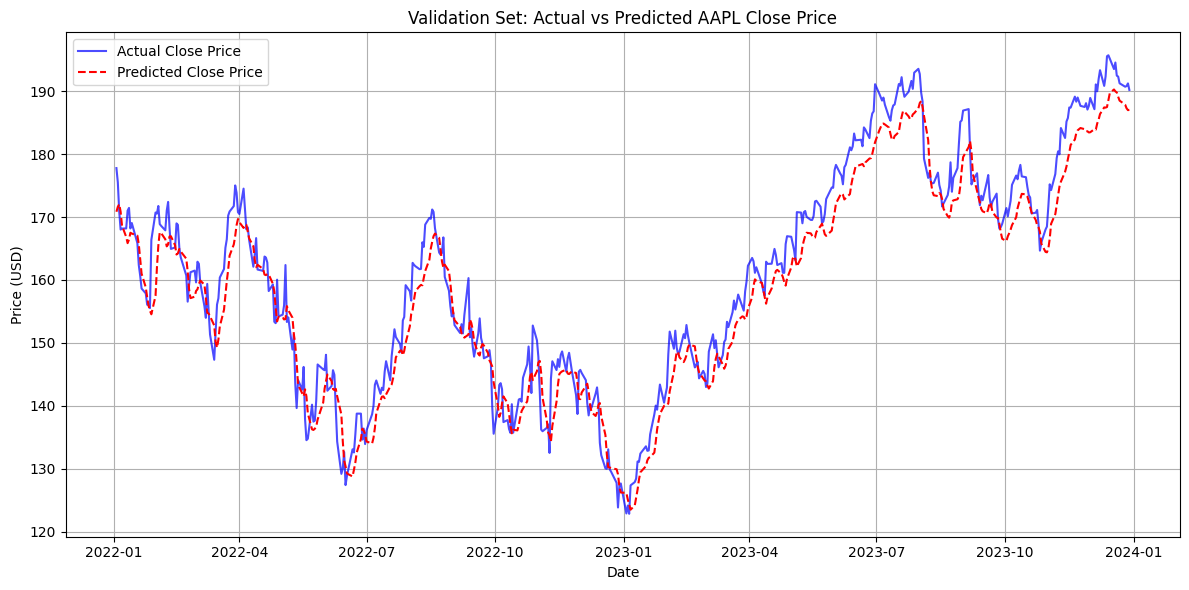

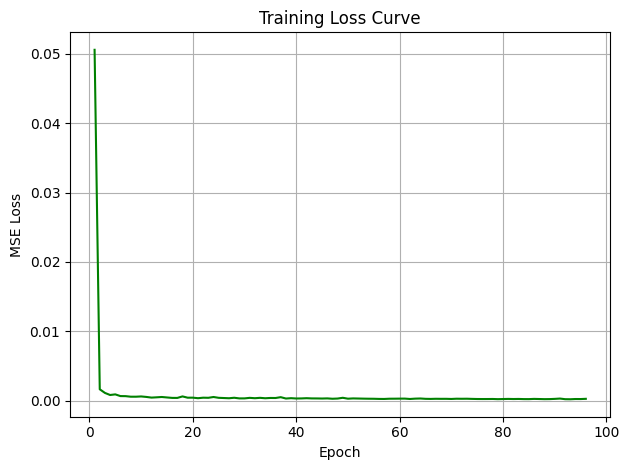

In [147]:

model.eval()
final_val_preds = []
final_val_trues = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        preds = model(X_batch)

        final_val_preds.append(preds.cpu().numpy())
        final_val_trues.append(y_batch.cpu().numpy())

val_preds = np.vstack(val_preds_list)
val_trues = np.vstack(val_trues_list)

val_preds_actual = scaler.inverse_transform(val_preds)
val_trues_actual = scaler.inverse_transform(val_trues)

val_rmse = np.sqrt(mean_squared_error(val_trues_actual, val_preds_actual))

print("\n" + "="*40)
print(f"Validation Evaluation Results:")
print(f"Validation RMSE: ${val_rmse:.4f}")
print("="*40)


plt.figure(figsize=(12, 6))
plt.plot(val_df.index, val_trues_actual, label='Actual Close Price', color='blue', alpha=0.7)
plt.plot(val_df.index, val_preds_actual, label='Predicted Close Price', color='red', linestyle='--')
plt.title('Validation Set: Actual vs Predicted AAPL Close Price')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.plot(range(1, len(train_losses) + 1), train_losses, label='Training MSE Loss', color='green')
plt.title('Training Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.grid(True)
plt.tight_layout()


Test Set RMSE: $8.5583


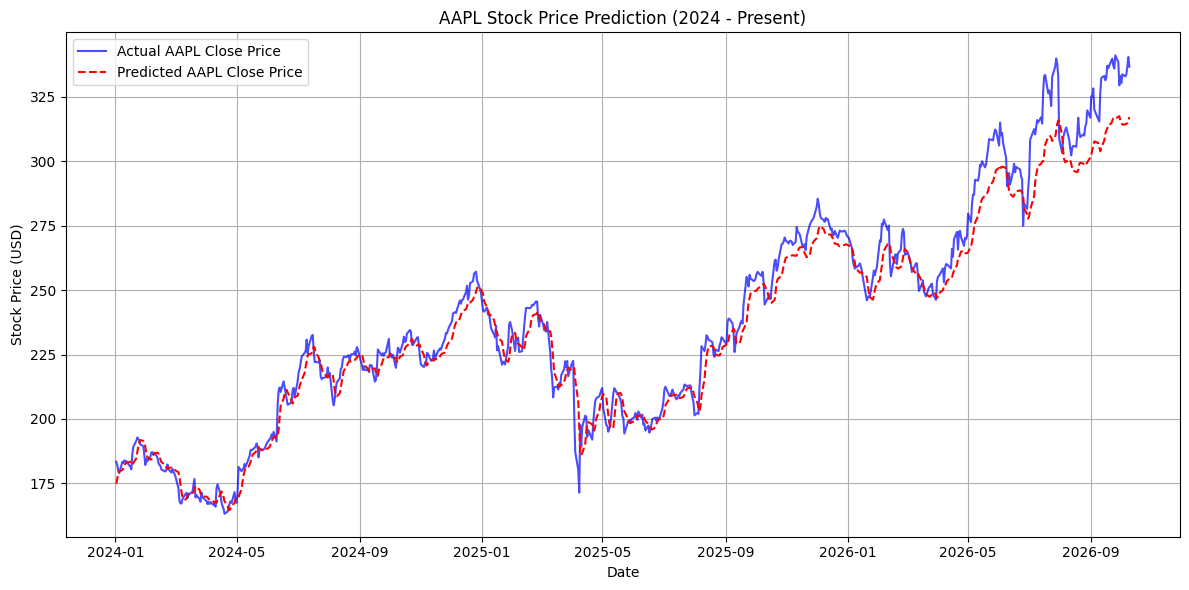

In [148]:
test_preds = []
with torch.no_grad():
    for X_batch, _ in test_loader:
        X_batch = X_batch.to(device)
        preds = model(X_batch)
        test_preds.extend(preds.cpu().numpy())

test_preds = np.array(test_preds)

y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))
y_test_pred = scaler.inverse_transform(test_preds)

test_rmse = np.sqrt(mean_squared_error(y_test_actual, y_test_pred))
print(f"\n==========================================")
print(f"Test Set RMSE: ${test_rmse:.4f}")
print(f"==========================================")


test_dates = test_df.index
plt.figure(figsize=(12, 6))
plt.plot(test_dates, y_test_actual, label='Actual AAPL Close Price', color='blue', alpha=0.7)
plt.plot(test_dates, y_test_pred, label='Predicted AAPL Close Price', color='red', linestyle='--')
plt.title('AAPL Stock Price Prediction (2024 - Present)')
plt.xlabel('Date')
plt.ylabel('Stock Price (USD)')
plt.legend()
plt.grid(True)
plt.tight_layout()
